# M00 Overview | Turning a Model into a Graph: torch.export, ATen, and fx

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m00_export_basics/00_overview.ipynb)

Every step of PT2E quantization works on a "computation graph". This chapter first answers four questions: why we need this graph, why every operation on it is an ATen op, what the graph is made of, and how to modify it.
The next four notebooks (M00-1 to M00-4) then go through them hands-on.

In [1]:
#| include: false
# When running on Google Colab: download the course code and install the packages (takes a few minutes the first time).
# When running on your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # let the notebook import this course's common/
    os.chdir(f"{repo}/en/m00_export_basics")

In [2]:
#| echo: false
import copy

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.export import export

from common.graph_utils import short
from common.models import example_inputs, get_model
from common.pt2e import MinMaxObserver, export_module, quiet
from common.viz import draw, draw_stages, table

quiet()
_ = torch.manual_seed(0)

## Why We Need a Graph

Quantization makes decisions tensor by tensor: should this tensor be stored as int8, and with what scale? To make these decisions you first need to know, for every tensor, **which operation produces it and which operations use it**. That is the data flow of the whole model.

But the `forward` of an `nn.Module` is arbitrary Python: it can contain loops, ifs, calls to other modules, calls to functions. Without running it, it is hard to say what it computes; if you do run it, you only get numbers, not structure.

So the first step is to "capture" the model as a graph: each operation is a node, and the edges between nodes are the flow of tensors. The full name of PT2E is PyTorch 2 **Export** quantization, and the capture is done by `torch.export`.
Everything after that (annotation, inserting observers, replacing them with quantize/dequantize) reads and edits this graph.

## Why Everything on the Graph Is an ATen Op

The graph ends up being handed to a backend: XNNPACK, ONNX Runtime, various NPUs. The first thing a backend does with the graph is check node by node, "do I have a kernel for this operation?"
This requires the operation names on the graph to be **uniform** and **finite in number**, so the backend can compare them against its list of supported ops.

The older fx capture, `torch.fx.symbolic_trace`, cannot do this. Take the same model (conv → relu → mean → linear), write it in three Python styles, and capture each with both methods:

In [3]:
#| echo: false
class FunctionalStyle(nn.Module):
    def __init__(self):
        super().__init__()
        self.w = nn.Parameter(torch.randn(8, 3, 3, 3))
        self.fc_w = nn.Parameter(torch.randn(4, 8))

    def forward(self, x):
        return F.linear(F.relu(F.conv2d(x, self.w, padding=1)).mean((2, 3)), self.fc_w)


class ModuleStyle(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(3, 8, 3, padding=1, bias=False)
        self.act = nn.ReLU()
        self.fc = nn.Linear(8, 4, bias=False)

    def forward(self, x):
        return self.fc(self.act(self.conv(x)).mean((2, 3)))


class SequentialStyle(nn.Module):
    def __init__(self):
        super().__init__()
        self.body = nn.Sequential(nn.Conv2d(3, 8, 3, padding=1, bias=False), nn.ReLU())
        self.fc = nn.Linear(8, 4, bias=False)

    def forward(self, x):
        return self.fc(self.body(x).mean((2, 3)))


def fx_ops(gm):
    out = []
    for n in gm.graph.nodes:
        if n.op == "call_module":
            out.append(f"module {type(gm.get_submodule(n.target)).__name__}({n.target})")
        elif n.op == "call_function":
            out.append(f"function {n.target.__name__}")
        elif n.op == "call_method":
            out.append(f"method {n.target}")
    return out


styles = [("F.conv2d, F.relu…", FunctionalStyle), ("nn.Conv2d, nn.ReLU…", ModuleStyle), ("nn.Sequential", SequentialStyle)]
ex_small = (torch.randn(2, 3, 8, 8),)
rows, export_lists = [], []
for label, cls in styles:
    e = [n.target for n in export(cls().eval(), ex_small).module().graph.nodes if n.op == "call_function"]
    export_lists.append(e)
    rows.append([label, " → ".join(fx_ops(torch.fx.symbolic_trace(cls()))), " → ".join(short(t) for t in e)])
assert all(e == export_lists[0] for e in export_lists)
table(rows, ["Style", "torch.fx.symbolic_trace nodes", "torch.export nodes"])

Style,torch.fx.symbolic_trace nodes,torch.export nodes
"F.conv2d, F.relu…",function conv2d → function relu → method mean → function linear,conv2d → relu → mean → linear
"nn.Conv2d, nn.ReLU…",module Conv2d(conv) → module ReLU(act) → method mean → module Linear(fc),conv2d → relu → mean → linear
nn.Sequential,module Conv2d(body.0) → module ReLU(body.1) → method mean → module Linear(fc),conv2d → relu → mean → linear


- The `symbolic_trace` graph follows the way the model is written: `nn.Conv2d` stays a module (even its path in the model, `body.0`, is kept), `F.conv2d` is a Python function, and `.mean()` is a method.
  The same conv comes in several shapes, so a backend would have to recognize every `nn.Module` class and every Python style before it could decide whether it supports them.
- The `torch.export` graph is the same sequence of `aten.*` ops no matter how the model is written, and the module hierarchy is flattened.

**ATen** is PyTorch's core tensor library; every PyTorch operation ultimately lands on an op defined there. The official `torch.export` documentation states that the exported graph contains only ATen ops (and user-defined ops), and that it is flat with no Python semantics
([torch.export](https://docs.pytorch.org/docs/main/user_guide/torch_compiler/export.html)).
Within ATen there is a selected set of about 180 ops called **Core ATen**, which the documentation says is designed to be the IR that backends target ([IRs](https://docs.pytorch.org/docs/main/user_guide/torch_compiler/torch.compiler_ir.html)).
A backend only needs to implement this set of ops to handle any exported model.

ATen can be decomposed to different depths; the export documentation lists three levels:

| Level | How to get it | Number of ops (docs) | Use |
|---|---|---|---|
| export default | `torch.export.export()` | about 3000 | PT2E annotates at this level |
| in-place mutation removed | `ep.run_decompositions({})` | about 2000 | inference deployment |
| Core ATen | `ep.run_decompositions()` | about 180 | backends that want to minimize the ops they implement |

PT2E annotates at the top level: `conv2d` and `batch_norm` are still single ops, so the "conv → bn → relu" pattern is easiest to recognize. How deep to decompose is up to the backend (M00-3).

There is also a separate reason `torch.export` replaces `symbolic_trace`: it traces at the Python bytecode level with TorchDynamo, so it can capture programs that symbolic_trace cannot (for example, branches that depend on tensor shape).
That is a question of "can the graph be captured", which is a different matter from "what vocabulary the graph uses".

## A First Example

This project's `ConvBnReLU`:

```python
class ConvBnReLU(nn.Module):
    def __init__(self, cin=3, cout=8, bias=False):
        super().__init__()
        self.conv = nn.Conv2d(cin, cout, 3, padding=1, bias=bias)
        self.bn = nn.BatchNorm2d(cout)
        self.relu = nn.ReLU()

    def forward(self, x):
        return self.relu(self.bn(self.conv(x)))
```

The graph after `torch.export.export(model.eval(), (x,)).module()`:

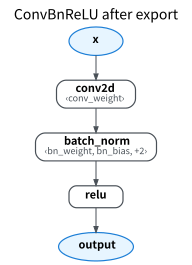

In [4]:
#| echo: false
model = get_model("conv_bn_relu").eval()
ex = example_inputs()
ep = export(model, ex)
gm = ep.module()
draw(gm, title="ConvBnReLU after export")

The three modules become three operation nodes: `conv2d`, `batch_norm`, and `relu`. The weight, the BN parameters, and the running stats are written inside `‹…›` under the node that uses them; they are also nodes on the graph (`get_attr`), just not drawn separately.
The input `x` and the output `output` are the two ends of the graph.

## Definitions

### ExportedProgram and GraphModule

`torch.export.export(model, args)` returns an **ExportedProgram** (`ep`), which holds three things:

- `ep.graph`: the graph itself. Parameters, buffers, and user inputs are **all inputs of the graph** (placeholders).
- `ep.graph_signature`: says whether each placeholder is a parameter, a buffer, or a user input, and which field of the original model it corresponds to.
- `ep.state_dict`: the values of the parameters and buffers.

`ep.module()` binds the state_dict back according to the signature and returns a directly callable **GraphModule**: parameters become `get_attr` nodes that read attributes off the module itself, leaving only `x` as a placeholder.
PT2E's `prepare_pt2e` takes this GraphModule (M00-1 Part A).

### Node

`gm.graph` inside a GraphModule is a sequence of **nodes**, in execution order. An exported graph has only five kinds of node (`node.op`):

| `node.op` | Meaning | Example |
|---|---|---|
| `placeholder` | an input of the graph | `x` |
| `get_attr` | reads a parameter or buffer on the GraphModule | `conv_weight` |
| `call_function` | calls a function; in an exported graph this is an ATen op | `conv2d` |
| `call_module` | calls a submodule of the GraphModule | `_guards_fn` (input check); observers inserted later by prepare |
| `output` | the output of the graph | `output` |

Each node also has a few commonly used attributes: `target` (what it calls), `args` (which nodes or constants it takes), `users` (who uses it), and `meta` (information collected at export time, such as the output shape). Looking at the `conv2d` on the graph:

In [5]:
conv = next(n for n in gm.graph.nodes if n.name == "conv2d")
print(f"op     = {conv.op}")
print(f"target = {conv.target}")
print(f"args   = {conv.args}")
print(f"users  = {list(conv.users)}")
print(f"shape of meta['val'] = {list(conv.meta['val'].shape)}")
assert conv.op == "call_function" and conv.target is torch.ops.aten.conv2d.default

op     = call_function
target = aten.conv2d.default
args   = (x, conv_weight, None, [1, 1], [1, 1])
users  = [batch_norm]
shape of meta['val'] = [2, 8, 16, 16]


`x` and `conv_weight` in `args` are nodes (this is how edges arise); `None` is the bias (this conv has no bias), and `[1, 1]` are the stride and padding, constants written directly into the arguments.
The reverse direction of `users` is `args`: `batch_norm` takes `conv2d`, so `batch_norm` is in `conv2d.users`. Quantization annotations will also be written into `meta` later (M01-2).

### Names of ATen Ops

`torch.ops.aten.conv2d.default` has three parts: `aten` is the namespace, `conv2d` is the op, and `default` is the overload (the same op has different versions for different argument types, e.g. `add.Tensor` and `add.Scalar`).
The `node.target` on the graph is exactly this object; a quantizer uses `node.target == torch.ops.aten.conv2d.default` to find convs (M00-1 Part B).

### The Mode Is Fixed at Export Time

Exporting after `model.eval()` or after `model.train()` gives different graphs: the `training` argument of `batch_norm` is written as False or True, and the train mode graph has an extra node that updates `num_batches_tracked`.
An exported GraphModule can no longer be switched with `.train()` / `.eval()`. PTQ exports in eval mode, QAT in train mode (M00-2).

### Decomposition

Breaking a big op into smaller ops is called **decomposition**, done with `ep.run_decompositions(table)`. For example, `batch_norm` is decomposed into `_native_batch_norm_legit_no_training` + `getitem`; with the Core ATen table, `conv2d` also becomes `convolution` (M00-3).

## The Four Graph-Editing Actions

PT2E's `prepare_pt2e` and `convert_pt2e` both edit the graph. There are only four basic editing actions:

| Action | API | Example |
|---|---|---|
| Insert | call `graph.call_module` or `graph.call_function` inside `graph.inserting_after(n)` | create an observer after relu |
| Rewire | `n.replace_all_uses_with(new, delete_user_cb=...)` | the node that used to take relu now takes the observer |
| Replace | insert the new one → rewire → `graph.erase_node(old)` | convert replaces an observer with q/dq |
| Clean up | `graph.eliminate_dead_code()`, `graph.lint()` | delete nodes nobody uses, check the structure |

After editing you must call `gm.recompile()` so that the GraphModule's forward is regenerated from the new graph.
The figure below uses these actions to manually insert a `MinMaxObserver` after the relu in conv → relu, which is exactly what `prepare_pt2e` does:

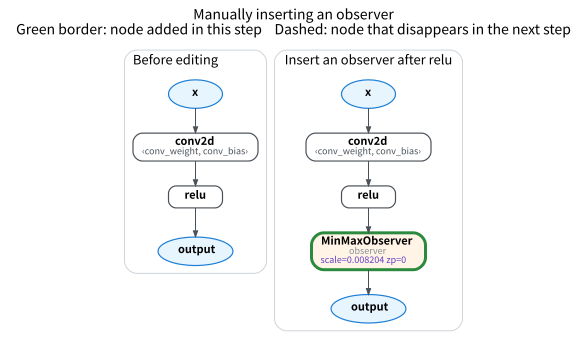

In [6]:
#| echo: false
gm_before = export_module(get_model("conv_relu").eval(), example_inputs(4))
gm_after = copy.deepcopy(gm_before)
relu = next(n for n in gm_after.graph.nodes if n.name == "relu")
gm_after.add_submodule("observer", MinMaxObserver())
with gm_after.graph.inserting_after(relu):
    obs = gm_after.graph.call_module("observer", (relu,))
relu.replace_all_uses_with(obs, delete_user_cb=lambda user: user is not obs)
gm_after.recompile()
with torch.no_grad():
    x = example_inputs(4)[0]
    assert torch.equal(gm_before(x), gm_after(x))  # the observer only observes; it does not change values
draw_stages([(gm_before, "Before editing"), (gm_after, "Insert an observer after relu")], title="Manually inserting an observer")

The observer (green box) is inserted between relu and output, and the output that used to take relu now takes the observer. The observer passes its input through unchanged, so the outputs before and after editing are identical.
The details of each action and the common pitfalls (for example, without `delete_user_cb` the new node ends up taking itself) are in M00-4.

## Summary and Chapter Map

- Quantization needs to know where each tensor comes from and where it goes, so we first capture the model as a graph with `torch.export`.
- The graph contains only ATen ops: no matter how the Python is written, backends and quantizers only need to recognize this set of ops.
- The graph is made of nodes; a node's `op`, `target`, `args`, `users`, and `meta` are vocabulary used in every later chapter.
- Graph editing is insert, rewire, replace, and clean up, then finally `recompile`; prepare and convert are both combinations of these actions.

| notebook | Question it answers |
|---|---|
| [M00-1 The Exported Graph](01_export_and_inspect.ipynb) | How ExportedProgram differs from GraphModule, what is on a node, what ATen is, and why different styles become the same sequence of ops |
| [M00-2 eval vs. train](02_eval_vs_train.ipynb) | How the mode is written into the graph, and why it cannot be switched after export |
| [M00-3 Decomposition](03_decomposition.ipynb) | How big ops are decomposed, and why PT2E annotates before decomposition |
| [M00-4 Graph Editing](04_fx_graph_editing.ipynb) | The six graph-editing steps, and the pitfall at each step |

What this chapter deliberately skips: dynamic shapes (`torch.export.Dim`; this project's `export_module()` only makes the batch dimension dynamic), control flow (`torch.cond`), custom ops, and saving/loading an ExportedProgram.

## References

- [torch.export official documentation](https://docs.pytorch.org/docs/main/user_guide/torch_compiler/export.html): ExportedProgram, graph signature, the three IR levels, and the comparison with `symbolic_trace`
- [IRs: Core ATen IR and Prims IR](https://docs.pytorch.org/docs/main/user_guide/torch_compiler/torch.compiler_ir.html): the Core ATen op list and its role
- [torch.fx official documentation](https://docs.pytorch.org/docs/stable/fx.html): the Graph, Node, and GraphModule APIs
- [ATen C++ documentation](https://docs.pytorch.org/cppdocs/); all ATen ops are defined in [`native_functions.yaml`](https://github.com/pytorch/pytorch/blob/main/aten/src/ATen/native/native_functions.yaml)
- [Some Basic Concepts of PyTorch FX Graph and Node](https://bobondemon.github.io/2025/07/29/%E7%AD%86%E8%A8%98-PyTorch-FX-%E7%9A%84-Graph-Node-%E4%B8%80%E4%BA%9B%E5%9F%BA%E7%A4%8E%E6%A6%82%E5%BF%B5/) (in Chinese): the doubly linked structure of nodes, `replace_all_uses_with`, and how `erase_node` keeps the graph consistent